# Setup

In [1]:
from pprint import pprint


# Seed
seed = 42

# Terminologies (wip)

- State
  - A shared data across running.
  - A node reads and updates the state.
  - e.g. `MessagesState`
- Reducer
  - A rule on how to apply a new state on existing state.
  - e.g. `MessagesState.messages`: appends.
- Node
  - An entity that reads / updates the state.
  - Could be any Python method or agent.
- Edge
  - A execution flow of nodes.

# 1. Graph

## 1.1. Simple Graph

<details>
<summary>Note) <code>builder.compile()</code></summary><br>

| Parameter | Default | Description |
|---|---|---|
| `checkpointer` | `None` | Saves execution checkpoints per thread for inspection and resumption. |
| `store` | `None` | Provides cross-thread storage; application code explicitly reads and writes data. |
| `cache` | `None` | Stores reusable node results; requires a node-level `cache_policy`. |
| `interrupt_before` | `None` | Pauses before specified nodes; accepts node names or `"*"` for all nodes. |
| `interrupt_after` | `None` | Pauses after specified nodes; accepts node names or `"*"` for all nodes. |
| `debug` | `False` | Enables execution debugging output. |
| `name` | `None` | Assigns a name to the compiled graph. |
| `transformers` | `None` | Adds custom transformers for v3 event streaming; leave unset for basic usage. |

</details>

<details>
<summary>Note) <code>graph</code> methods</summary><br>

| Method | Description |
|---|---|
| `get_state(config)` | Returns a StateSnapshot containing saved state, pending nodes, and metadata. |
| `get_state_history(config)` | Iterates over saved checkpoints, newest first. |
| `update_state(config, values)` | Creates a new checkpoint using the state's reducers; does not execute nodes. |
| `ainvoke(input, config)` | Asynchronously executes the graph and returns its result. |
| `astream(input, config, stream_mode=...)` | Asynchronously executes the graph and yields intermediate outputs. |

</details>

[values] {'x': 2, 'y': 3}
[updates] {'init': {'x': 2, 'y': 3}}
[values] {'x': 2, 'y': 3}
[updates] {'y_large': {'big': 3}}
[values] {'x': 2, 'y': 3, 'big': 3}
[updates] {'y_square': {'y': 9}}
[values] {'x': 2, 'y': 9, 'big': 3}


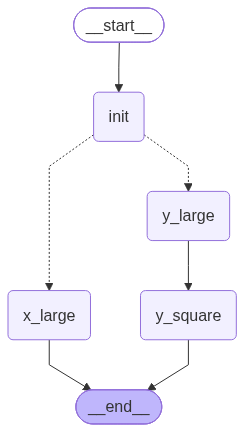

Final state: {'x': 2, 'y': 9, 'big': 3}

State history (last -> first):
{'x': 2, 'y': 9, 'big': 3}
{'x': 2, 'y': 3, 'big': 3}
{'x': 2, 'y': 3}
{'x': 2, 'y': 3}
{}


In [2]:
from typing import TypedDict, NotRequired
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from IPython.display import Image


# 1. State
class State(TypedDict):
    x: int
    y: int
    big: NotRequired[int]


# 2. Nodes
def init_values(state: State):
    return State(x=state['x'], y=state['y'])

def x_large(state: State):
    return {'big': state['x']}

def y_large(state: State):
    return {'big': state['y']}

def y_square(state: State):
    return {'y': state['y'] ** 2}


# 3. Conditional edges
def larger_int(state: State):
    x = state['x']
    y = state['y']

    if x > y:
        return 'x_large'
    elif x <= y:
        return 'y_large'


# 4. Graph
builder = StateGraph(State)

builder.add_node('init', init_values)
builder.add_node('x_large', x_large)

builder.add_edge(START, 'init')     # builder.set_entry_point('init')
builder.add_conditional_edges('init', larger_int, ['x_large', 'y_large'])
builder.add_sequence([('y_large', y_large), ('y_square', y_square)])
builder.add_edge('x_large', END)
builder.add_edge('y_square', END)

graph = builder.compile(
    name='prac',
    checkpointer=InMemorySaver(),
    interrupt_before=None,
    interrupt_after=None,
    debug=True,
)
config = {'configurable': {'thread_id': 'prac'}}


# 5. Run
response = graph.invoke(
    input=State(x=2, y=3),
    config=config,
)


# 6. Visualize
image_bytes = graph.get_graph().draw_mermaid_png(
    output_file_path='diagrams/1_simple_graph.png',
)
image = Image(image_bytes)

display(image)


# 7. State history
print(f"Final state: {graph.get_state(config).values}")

print("\nState history (last -> first):")
for history in graph.get_state_history(config):
    print(history.values)

## 1.2. Stream

<details>
<summary>Note) <code>stream_mode</code> list</summary><br>

| stream_mode | Description |
|---|---|
| `'updates'` | State updates returned by each node, together with the node name. |
| `'values'` | The complete State after each execution step. |
| `'messages'` | LLM output chunks and metadata as `(message_chunk, metadata)`, not the entire message history. |
| `'custom'` | Custom data explicitly emitted using `get_stream_writer()`. |

</details>

In [3]:
print("stream_mode='updates'")
response_stream = graph.stream(
    input=State(x=2, y=3),
    stream_mode='updates',
    config=config,
)

for event in response_stream:
    print(event)


print("\nstream_mode='values'")
response_stream = graph.stream(
    input=State(x=2, y=3),
    stream_mode='values',
    config=config,
)

for event in response_stream:
    print(event)

stream_mode='updates'
[values] {'x': 2, 'y': 3, 'big': 3}
[updates] {'init': {'x': 2, 'y': 3}}
{'init': {'x': 2, 'y': 3}}
[values] {'x': 2, 'y': 3, 'big': 3}
[updates] {'y_large': {'big': 3}}
{'y_large': {'big': 3}}
[values] {'x': 2, 'y': 3, 'big': 3}
[updates] {'y_square': {'y': 9}}
{'y_square': {'y': 9}}
[values] {'x': 2, 'y': 9, 'big': 3}

stream_mode='values'
[values] {'x': 2, 'y': 3, 'big': 3}
{'x': 2, 'y': 3, 'big': 3}
[updates] {'init': {'x': 2, 'y': 3}}
[values] {'x': 2, 'y': 3, 'big': 3}
{'x': 2, 'y': 3, 'big': 3}
[updates] {'y_large': {'big': 3}}
[values] {'x': 2, 'y': 3, 'big': 3}
{'x': 2, 'y': 3, 'big': 3}
[updates] {'y_square': {'y': 9}}
[values] {'x': 2, 'y': 9, 'big': 3}
{'x': 2, 'y': 9, 'big': 3}


## 1.3. Control API

In [4]:
from typing import TypedDict, NotRequired
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from IPython.display import Image


# 1. State
class State(TypedDict):
    x: int
    y: int
    big: NotRequired[int]


# 2. Nodes
def init_values(state: State):
    return State(x=state['x'], y=state['y'])

def x_large(state: State):
    return {'big': state['x']}

def y_large(state: State):
    return {'big': state['y']}

def y_square(state: State):
    return {'y': state['y'] ** 2}


# 3. Conditional edges
def larger_int(state: State):
    x = state['x']
    y = state['y']

    if x > y:
        return 'x_large'
    elif x <= y:
        return 'y_large'

### 1.2.1. `Command`

{'x': 2, 'y': 9, 'big': 3}


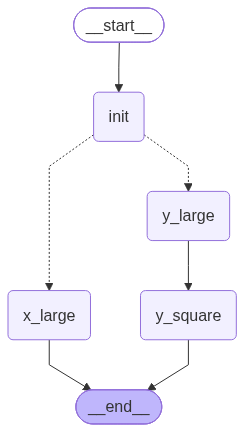

In [5]:
from typing import Literal
from langgraph.types import Command

# 4. Command: node + routing.
def init(state: State) -> Command[Literal["x_large", "y_large"]]:
    return Command(
        update=init_values(state),      # node.
        goto=larger_int(state),         # conditional edge.
    )


# 5. Graph
builder = StateGraph(State)

builder.add_node("init", init)          # init_values -> larger_int.
builder.add_node("x_large", x_large)
builder.add_sequence([("y_large", y_large), ("y_square", y_square)])

builder.add_edge(START, "init")
builder.add_edge("x_large", END)
builder.add_edge("y_square", END)

graph = builder.compile(
    name="prac_command",
    checkpointer=InMemorySaver(),
)
config = {"configurable": {"thread_id": "prac_command"}}


# 6. Run
response = graph.invoke(State(x=2, y=3), config)
print(response)  # Expected: {"x": 2, "y": 9, "big": 3}


# 7. Visualize
image_bytes = graph.get_graph().draw_mermaid_png(
    output_file_path='diagrams/1_simple_graph.png',
)
image = Image(image_bytes)

display(image)

### 1.2.2. `Send`

{'x': 2, 'y': 9, 'big': 3}


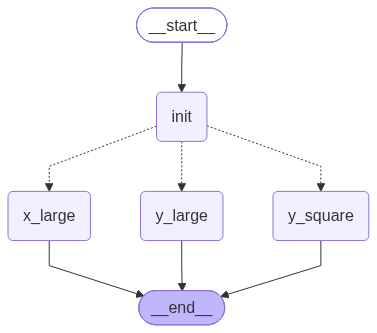

In [6]:
from langgraph.types import Send


def dispatch(state: State):
    payload = State(x=state["x"], y=state["y"])

    if state["x"] > state["y"]:
        return [Send("x_large", payload)]

    # Both tasks receive the original values.
    return [
        Send("y_large", payload),
        Send("y_square", payload),
    ]


# 4. Graph
builder = StateGraph(State)

builder.add_node("init", init_values)
builder.add_node("x_large", x_large)
builder.add_node("y_large", y_large)
builder.add_node("y_square", y_square)

builder.add_edge(START, "init")
builder.add_conditional_edges(
    "init", dispatch, ["x_large", "y_large", "y_square"],
)

# No sequence: dispatched tasks run in parallel.
builder.add_edge("x_large", END)
builder.add_edge("y_large", END)
builder.add_edge("y_square", END)

graph = builder.compile(
    name="prac_send",
    checkpointer=InMemorySaver(),
)
config = {"configurable": {"thread_id": "prac_send"}}


# 5. Run
response = graph.invoke(State(x=2, y=3), config)
print(response)  # Expected: {"x": 2, "y": 9, "big": 3}


# 6. Visualize
image_bytes = graph.get_graph().draw_mermaid_png(
    output_file_path='diagrams/1_simple_graph.png',
)
image = Image(image_bytes)

display(image)

### 1.2.3. `interrupt`

{'question': 'Should we square y?', 'y': 3}
{'x': 2, 'y': 9, 'big': 3}


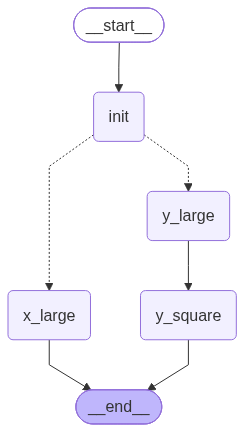

In [7]:
from langgraph.types import Command, interrupt


def y_square_with_approval(state: State):
    approved = interrupt({
        'question': "Should we square y?",
        'y': state['y'],
    })

    return y_square(state) if approved is True else {}


# 4. Graph
builder = StateGraph(State)

builder.add_node('init', init_values)
builder.add_node('x_large', x_large)
builder.add_sequence([
    ('y_large', y_large),
    ('y_square', y_square_with_approval),
])

builder.add_edge(START, 'init')
builder.add_conditional_edges('init', larger_int, ['x_large', 'y_large'])
builder.add_edge('x_large', END)
builder.add_edge('y_square', END)

graph = builder.compile(
    name='prac_interrupt',
    checkpointer=InMemorySaver(),
)
config = {'configurable': {'thread_id': 'prac_interrupt'}}


# 5. Run: until approval is required.
paused = graph.invoke(State(x=2, y=3), config)
print(paused['__interrupt__'][0].value)     # {"question": "Should we square y?", "y": 3}


# 6. Resume: using the same thread.
response = graph.invoke(Command(resume=True), config)
print(response)  # {'x': 2, 'y': 9, 'big': 3}


# 7. Visualize
image_bytes = graph.get_graph().draw_mermaid_png(
    output_file_path='diagrams/1_simple_graph.png',
)
image = Image(image_bytes)

display(image)

## 1.4. Chat & Tool Node

================================ System Message ================================

You are a helpful assistant. If the user's name is unknown, call ask_user_name. Once the name is known, answer directly.
================================ Human Message =================================

What is my name?
================================== Ai Message ==================================
Tool Calls:
  ask_user_name (c8107662-2100-40a5-a08a-7d52a2763b75)
 Call ID: c8107662-2100-40a5-a08a-7d52a2763b75
  Args:
================================= Tool Message =================================
Name: ask_user_name

yana
================================== Ai Message ==================================

Your name is yana.
Model calls: 2


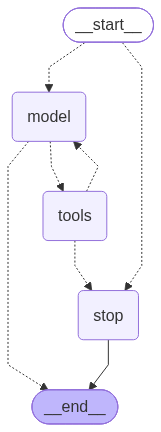

In [8]:
from langchain_ollama import ChatOllama
from langchain_core.tools import tool
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.prebuilt import ToolNode
from IPython.display import Image


# 1. Chat model
chat = ChatOllama(
    model="qwen3:4b",
    top_k=10,
    top_p=0.9,
    temperature=1.0,
    reasoning=True,
    seed=42,
)

# 2. Tools
@tool
def ask_user_name() -> str:
    """Ask user for name and return."""
    return 'yana'

chat_with_tools = chat.bind_tools([ask_user_name])


# 3. State
class State(MessagesState):
    step_count: int


# 4. Nodes
def call_model(state: State):
    """Call the LLM and update state."""
    reply = chat_with_tools.invoke(state["messages"])

    return {
        "messages": [reply],
        "step_count": state["step_count"] + 1,
    }


def stop(state: State):
    """Stop when the maximum number of model calls is reached."""
    return {
        "messages": [
            AIMessage(content="Stopped: maximum model calls reached!")
        ],
    }


# 5. Routing functions
max_steps = 3

def check_budget(state: State):
    if state["step_count"] < max_steps:
        return "model"
    return "stop"


def route_response(state: State):
    if state["messages"][-1].tool_calls:
        return "tools"
    return END


# 6. Graph
builder = StateGraph(State)

builder.add_node("model", call_model)
builder.add_node("tools", ToolNode([ask_user_name], handle_tool_errors=True))
builder.add_node("stop", stop)

builder.add_conditional_edges(START, check_budget, ["model", "stop"])
builder.add_conditional_edges("model", route_response, ["tools", END])
builder.add_conditional_edges("tools", check_budget, ["model", "stop"])
builder.add_edge("stop", END)

graph = builder.compile()


# 7. Run
system_prompt = (
    "You are a helpful assistant. "
    "If the user's name is unknown, call ask_user_name. "
    "Once the name is known, answer directly."
)

response = graph.invoke(
    {
        "messages": [
            SystemMessage(content=system_prompt),
            HumanMessage(content="What is my name?"),
        ],
        "step_count": 0,
    },
    config={"recursion_limit": 2 * max_steps + 5},
)

for message in response["messages"]:
    message.pretty_print()

print("Model calls:", response["step_count"])


# 8. Visualize
image_bytes = graph.get_graph().draw_mermaid_png(
    output_file_path='diagrams/1_simple_graph.png',
)
image = Image(image_bytes)

display(image)

## 1.5. Agent Node

================================ Human Message =================================

What is my name?
================================== Ai Message ==================================
Tool Calls:
  ask_user_name (ed637ccb-933e-483b-8ffd-c4d3e0693d02)
 Call ID: ed637ccb-933e-483b-8ffd-c4d3e0693d02
  Args:
================================= Tool Message =================================
Name: ask_user_name

yana
================================== Ai Message ==================================

Your name is Yana.


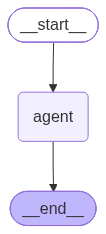

In [9]:
from langchain_ollama import ChatOllama
from langchain.agents import create_agent
from langchain_core.tools import tool
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from langgraph.graph import StateGraph, MessagesState, START, END
from langchain.agents.middleware import ModelCallLimitMiddleware
from IPython.display import Image


# 1. Chat model
chat = ChatOllama(
    model='qwen3:4b',
    top_k=10,
    top_p=0.9,
    temperature=1.0,
    reasoning=True,
    seed=seed,
)

# 2. Tools
@tool
def ask_user_name() -> str:
    """Ask user for name and return."""
    return 'yana'


# 3. Agent: manages the internal model-tool loop.
agent = create_agent(
    model=chat,
    tools=[ask_user_name],
    system_prompt=(
        "If the user's name is unknown, call ask_user_name. "
        "Once the name is known, answer directly."
    ),
    middleware=[
        ModelCallLimitMiddleware(run_limit=3, exit_behavior="end"),
    ],
)


# 4. Graph: treats the entire agent as one node.
builder = StateGraph(MessagesState)
builder.add_node("agent", agent)
builder.add_edge(START, "agent")
builder.add_edge("agent", END)

graph = builder.compile()


# 5. Run
response = graph.invoke({
    "messages": [HumanMessage(content="What is my name?")],
})

for message in response["messages"]:
    message.pretty_print()


# 6. Visualize
image_bytes = graph.get_graph().draw_mermaid_png(
    output_file_path='diagrams/1_agent_graph.png',
)
image = Image(image_bytes)

display(image)

## 1.6. Reducer

3
[2, 3]


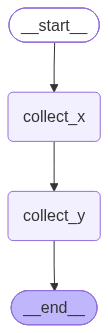

In [10]:
from typing import TypedDict, NotRequired, Annotated
from operator import add
from langgraph.graph import StateGraph, START, END


# 1. State
class State(TypedDict):
    x: int
    y: int
    latest: NotRequired[int]                # default: overwrite.
    candidates: Annotated[list[int], add]   # reducer: concatenate.


# 2. Nodes
def collect_x(state: State):
    return {
        'latest': state['x'],
        'candidates': [state['x']],
    }


def collect_y(state: State):
    # Return only the new item, not the accumulated list.
    return {
        'latest': state['y'],
        'candidates': [state['y']],
    }

# 3. Graph
builder = StateGraph(State)
builder.add_sequence([
    ('collect_x', collect_x),
    ('collect_y', collect_y),
])
builder.add_edge(START, 'collect_x')
builder.add_edge('collect_y', END)

graph = builder.compile()


# 4. Run
response = graph.invoke({'x': 2, 'y': 3, 'candidates': []})

print(response['latest'])      # 3 (2 was overwritten)
print(response['candidates'])  # [2, 3] (both were retained)


# 5. Visualize
image_bytes = graph.get_graph().draw_mermaid_png()
image = Image(image_bytes)

display(image)

## 1.7. Parallel Aggregation

[2, 3]
3


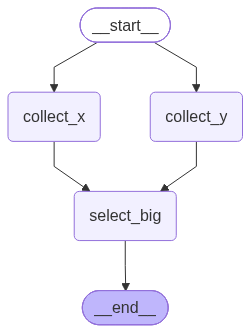

In [11]:
from typing import TypedDict, NotRequired, Annotated
from operator import add
from langgraph.graph import StateGraph, START, END


# 1. State
class State(TypedDict):
    x: int
    y: int
    candidates: Annotated[list[int], add]
    big: NotRequired[int]


# 2. Nodes
def collect_x(state: State):
    return {"candidates": [state["x"]]}


def collect_y(state: State):
    return {"candidates": [state["y"]]}


def select_big(state: State):
    return {"big": max(state["candidates"])}


# 3. Graph
builder = StateGraph(State)
builder.add_node("collect_x", collect_x)
builder.add_node("collect_y", collect_y)
builder.add_node("select_big", select_big)

# Fan-out: execute both collectors in parallel.
builder.add_edge(START, "collect_x")
builder.add_edge(START, "collect_y")

# Join: execute select_big only after both collectors finish.
builder.add_edge(["collect_x", "collect_y"], "select_big")
builder.add_edge("select_big", END)

graph = builder.compile()


# 4. Run
response = graph.invoke({"x": 2, "y": 3, "candidates": []})

print(sorted(response["candidates"]))  # [2, 3]
print(response["big"])                 # 3


# 5. Visualize
image_bytes = graph.get_graph().draw_mermaid_png()
image = Image(image_bytes)

display(image)

# 2. Hybrid Architecture

# 3. Subgraphs & Interfaces